# ED32 Material Model

This example performs a numerical tensile test on an ED32 (Elite Double 32) material. The material is modeled using an incompressible neo-Hookean constitutive law under plane-strain conditions. The numerical results are validated against the analytical solutions presented in [1].

## Reference

[1] Matteo Montanari, *Puncturing of soft tissues: experimental and fracture mechanics-based study*, 2023

In [ ]:
import dolfinx.fem.petsc
import dolfinx.io
from mpi4py import MPI
import viskex
import pyvista as pv
import ufl
import numpy as np
from petsc4py import PETSc
from pathlib import Path
import shutil
from matplotlib import pyplot as plt

comm = MPI.COMM_WORLD
rank = 0
pv.set_jupyter_backend("static")

# Results folder
results = Path("./results_ed32_plane_stress")
results.mkdir(exist_ok=True)

# Mesh properties
gdim    = 2
element = ("Lagrange", 2, (gdim,))

W = 15.0
L = 55.0
u = np.linspace(0, 55)
epsilon = u / L

# ED32 Material properties
mu = 0.405

lam = 1 + epsilon
P22_analytical      = mu * (lam - lam**(-2))
sigma22_analytical  = lam * P22_analytical

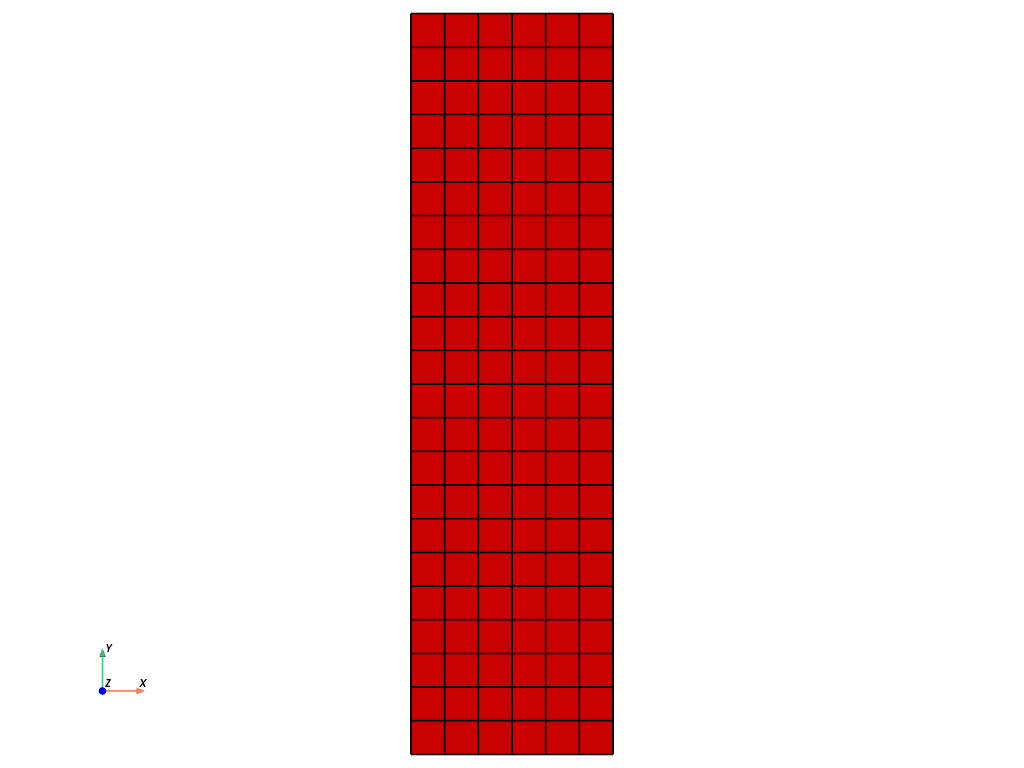

In [3]:
domain = dolfinx.mesh.create_rectangle(
    comm,
    points=((-W / 2, 0.0), (W / 2, L)),
    n=(6, 22),
    cell_type=dolfinx.mesh.CellType.quadrilateral
)

fdim = domain.topology.dim- 1
anchor = dolfinx.mesh.locate_entities_boundary(
    domain, 0, lambda x: np.isclose(x[0], 0.0) & np.isclose(x[1], 0.0)
)
top = dolfinx.mesh.locate_entities_boundary(
    domain, fdim, lambda x: np.isclose(x[1], L)
)
bottom = dolfinx.mesh.locate_entities_boundary(
    domain, fdim, lambda x: np.isclose(x[1], 0)
)

bottom_tags = dolfinx.mesh.meshtags(
    domain, fdim, bottom,
    np.full(bottom.shape, 1, dtype=np.int32)
)

viskex.dolfinx.plot_mesh(domain)

In [ ]:
V = dolfinx.fem.functionspace(domain, element)
uh = dolfinx.fem.Function(V, name="displacement")
v = ufl.TestFunction(V)
du = ufl.TrialFunction(V)

# Dirichlet
U = dolfinx.fem.Constant(domain, dolfinx.default_scalar_type(0.0))
anchor_dofs = dolfinx.fem.locate_dofs_topological(V.sub(0), 0, anchor)
top_dofs    = dolfinx.fem.locate_dofs_topological(V.sub(1), fdim, top)
bottom_dofs = dolfinx.fem.locate_dofs_topological(V.sub(1), fdim, bottom)

bc_anchor   = dolfinx.fem.dirichletbc(dolfinx.default_scalar_type(0.0), anchor_dofs, V.sub(0))
bc_top      = dolfinx.fem.dirichletbc(U, top_dofs, V.sub(1))
bc_bottom   = dolfinx.fem.dirichletbc(dolfinx.default_scalar_type(0.0), bottom_dofs, V.sub(1))

# ED32 Material
I   = ufl.Identity(2)
F   = ufl.variable(I + ufl.grad(uh))
J2  = ufl.det(F)
lam = 1.0 / J2
psi = 0.5 * mu * (ufl.tr(F.T * F) + lam**2 - 3.0)
Pi  = psi * ufl.dx
R   = ufl.derivative(Pi, uh, v)
K   = ufl.derivative(R, uh, du)

P = ufl.diff(psi, F)
sigma = P * F.T
P22_form        = dolfinx.fem.form(P[1, 1] * ufl.dx)
sigma22_form    = dolfinx.fem.form(sigma[1, 1] * ufl.dx)
area_form       = dolfinx.fem.form(dolfinx.fem.Constant(domain, dolfinx.default_scalar_type(1.0)) * ufl.dx)
area            = dolfinx.fem.assemble_scalar(area_form)

problem = dolfinx.fem.petsc.NonlinearProblem(
    R,
    uh,
    bcs=[bc_anchor, bc_top, bc_bottom],
    J=K,
    petsc_options_prefix="ed32_plane_stress_",
    petsc_options={
        "snes_type": "newtonls",
        "snes_linesearch_type": "bt",
        "snes_rtol": 1e-9,
        "snes_atol": 1e-10,
        "snes_max_it": 50,
        "snes_error_if_not_converged": True,
        "ksp_type": "preonly",
        "pc_type": "lu",
    },
)

V_output = dolfinx.fem.functionspace(domain, ("Lagrange", 1, (gdim,)))
u_output = dolfinx.fem.Function(V_output, name="displacement")

T_output        = dolfinx.fem.functionspace(domain, ("DG", 0, (3, 3)))
sigma_output    = dolfinx.fem.Function(T_output, name="cauchy_stress")
sigma_3d = ufl.as_tensor([
    [sigma[0, 0], sigma[0, 1], 0.0],
    [sigma[1, 0], sigma[1, 1], 0.0],
    [0.0, 0.0, 0.0],
])
sigma_expression = dolfinx.fem.Expression(sigma_3d, T_output.element.interpolation_points)

sigma_22    = np.zeros_like(u)
P_22        = np.zeros_like(u)
with dolfinx.io.XDMFFile(comm, str(results / "displacement.xdmf"), "w") as displacement_file, \
     dolfinx.io.XDMFFile(comm, str(results / "cauchy_stress.xdmf"), "w") as stress_file:
    displacement_file.write_mesh(domain)
    stress_file.write_mesh(domain)
    for step, displacement in enumerate(u):
        U.value = dolfinx.default_scalar_type(displacement)
        problem.solve()
        sigma_integral  = dolfinx.fem.assemble_scalar(sigma22_form)
        P_integral      = dolfinx.fem.assemble_scalar(P22_form)
        sigma_22[step]  = sigma_integral / area
        P_22[step]      = P_integral / area

        u_output.interpolate(uh)
        sigma_output.interpolate(sigma_expression)
        displacement_file.write_function(u_output, displacement)
        stress_file.write_function(sigma_output, displacement)



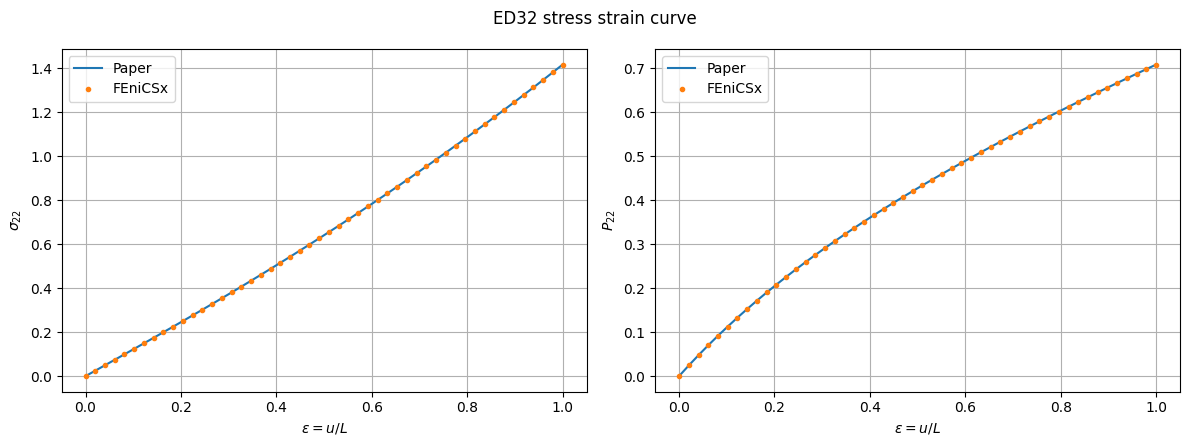

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax1 = axes[0]
ax2 = axes[1]

ax1.plot(epsilon, sigma22_analytical, "-", label="Paper")
ax1.plot(epsilon, sigma_22, ".", label="FEniCSx")
ax1.set_xlabel(r"$\epsilon = u/L$")
ax1.set_ylabel(r"$\sigma_{22}$")
ax1.grid(True)
ax1.legend()

ax2.plot(epsilon, P22_analytical, "-", label="Paper")
ax2.plot(epsilon, P_22, ".", label="FEniCSx")
ax2.set_xlabel(r"$\epsilon = u/L$")
ax2.set_ylabel(r"$P_{22}$")
ax2.grid(True)
ax2.legend()

fig.suptitle("ED32 stress strain curve")
fig.tight_layout()
plt.show()